In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
samples = np.array([50, 51, 53, 57, 65, 71, 80, 82, 84, 85, 88, 96, 99])

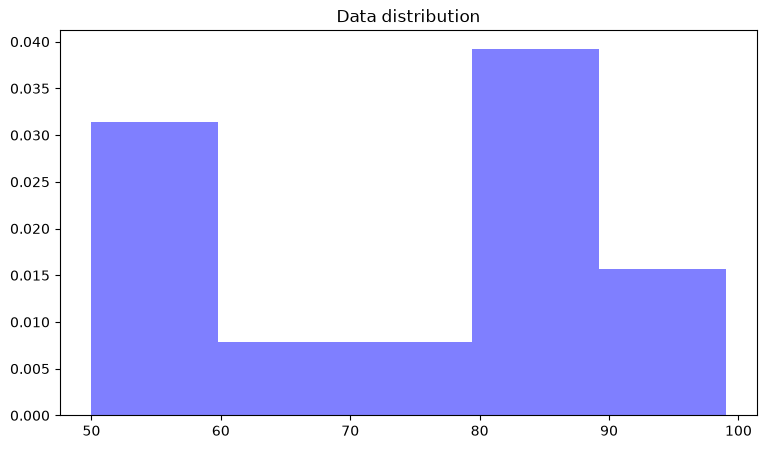

In [8]:
plt.figure(figsize=(9, 5))
plt.title('Data distribution')
plt.hist(samples, bins=5, density=True, alpha=0.5, color='blue')
plt.show()

Things we need to build KDE:
1. One kernel centered on each $x_i$
2. Each kernel has an area of $1/n$, where $n$ is the number of samples that we have
3. Give every kernel the same width (or bandwidth), say $h$
4. Find the estimate at any value by adding the heights of all the kernels there, which gives $\hat{f}(x)$

So, we should have:

$$
    \int \hat{f}(x) dx = 1
$$

and

$$
    \hat{f}(x) = \frac{1}{nh} \sum_{i=1}^{n} K\left(\frac{x-x_i}{h}\right)
$$

where

$$
    K(u) = \frac{e^{-u^2/2}}{\sqrt{(2 \pi)}}
$$

In [49]:
def kernel_density_estimation(samples, bandwidth=2, num_points=1000):
    x = np.linspace(samples.min() - 3 * bandwidth, samples.max() + 3 * bandwidth, num_points)
    y = np.zeros_like(x)

    for i, x_i in enumerate(x):
        for sample in samples:
            y[i] += np.exp(-((x_i - sample) / bandwidth)**2 / 2) / (np.sqrt(2 * np.pi))
        y[i] /= (len(samples) * bandwidth)

    return x, y

In [52]:
x, y = kernel_density_estimation(samples, bandwidth=4)

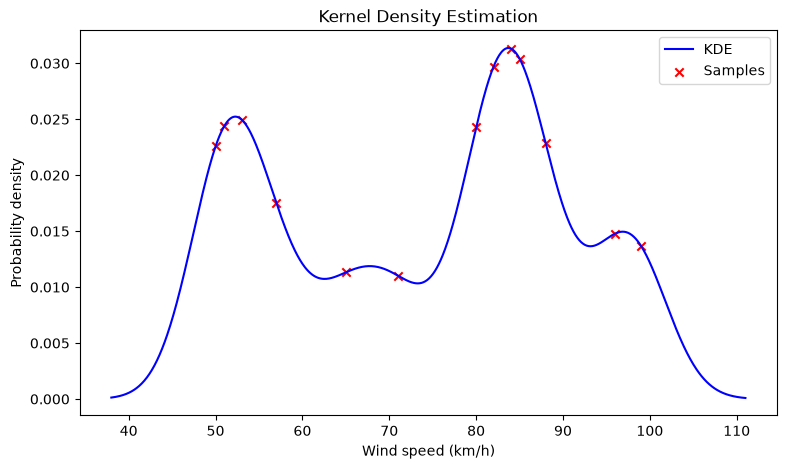

In [53]:
plt.figure(figsize=(9, 5))
plt.title('Kernel Density Estimation')
plt.plot(x, y, color='blue', label='KDE')
plt.scatter(samples, np.interp(samples, x, y), color='red', marker='x', label='Samples')
plt.xlabel('Wind speed (km/h)')
plt.ylabel('Probability density')
plt.legend()
plt.show()